# v11.1 · Extended training and checkpoint study for uncertainty-guided three-nudge identification

**Research goal:** Test whether a longer-trained SAC policy actually improves estimation of the asteroid's ten inertial parameters and the expected information added by successive virtual nudges. The model remains the **v11 information-only instantaneous-impulse surrogate**, not a spacecraft/CBF or physical-contact simulation.

**Quick vs full:** `QUICK_MODE = True` runs a lightweight end-to-end check. Switch to `False` for the extended study (default **120,000 SAC timesteps**). Both modes include mathematical tests, a continuous-estimation diagnostic, OED teacher generation, SAC training, held-out RL/OED/hybrid comparisons, covariance calibration, and decision-tree distillation.

**New in v11.1:** Automatic model **and replay-buffer** checkpoints, optional checkpoint recovery, a matched held-out comparison of 40k/80k/120k SAC models, training time reporting, and a fix to the per-nudge information plotting table. Results are written to separate `three_nudge_v11_extended_*` folders, leaving all existing v9/v10/v11 results unchanged.

**Scientific caution:** More SAC steps do **not** necessarily decrease parameter error. A checkpoint's reward is only a surrogate information objective; prioritize actual held-out mass/CoM/inertia errors and uncertainty coverage. Covariance is an approximate block construction, not a verified flight-ready posterior.


## 0 · Single quick/full switch and reproducibility

In [3]:
from pathlib import Path
import os, sys, subprocess, importlib.util, warnings, time, json, re
import numpy as np

# The one switch between the short check and the longer research workflow.
QUICK_MODE = False # False = full extended experiment
SEED = 19
NOISE_STD = 1e-4
CANDIDATES = 8 if QUICK_MODE else 64
SAMPLE_PERIOD_S = 1.0 if QUICK_MODE else 0.5
DIAGNOSTIC_PERIOD_S = 0.25
TEACHER_EPISODES = 12 if QUICK_MODE else 160
BC_EPOCHS = 8 if QUICK_MODE else 80
TRAIN_TIMESTEPS = 600 if QUICK_MODE else 120_000
CHECKPOINT_INTERVAL = 300 if QUICK_MODE else 10_000
EVALUATION_EPISODES = 4 if QUICK_MODE else 60
CALIBRATION_EPISODES = 8 if QUICK_MODE else 40
DISTILL_EPISODES = 18 if QUICK_MODE else 150
NOISE_SWEEP_EPISODES = 3 if QUICK_MODE else 20
CHECKPOINT_EVAL_EPISODES = 4 if QUICK_MODE else 16
STAGE_TIMESTEPS = (300,600) if QUICK_MODE else (40_000,80_000,120_000)

# Recovery only: set True AFTER an interrupted run, to resume from a checkpoint
# including its replay buffer. Leave False for a clean independent training run.
RESUME_TRAINING = False

cwd = Path.cwd().resolve()
ROOT = next((p for p in (cwd,*cwd.parents) if
             (p/'src'/'information_gain.py').exists() and (p/'model'/'asteroid.obj').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Copy the v11 source modules into active_inertial_id and open the notebook from that repository.')
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
OUT = ROOT/'results'/('three_nudge_v11_extended_quick' if QUICK_MODE else 'three_nudge_v11_extended_full')
OUT.mkdir(parents=True, exist_ok=True)
MODEL_PATH = OUT/'sac_uncertainty_v11_extended_final'
CHECKPOINT_DIR = OUT/'checkpoints'
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PREFIX = 'sac_uncertainty_v11_extended'
print('Repository:',ROOT,'\nKernel:',sys.executable,'\nMode:', 'QUICK' if QUICK_MODE else 'EXTENDED FULL')
print('Output folder:',OUT)
print('SAC training steps:',TRAIN_TIMESTEPS,'/ checkpoint every:',CHECKPOINT_INTERVAL)
print('Training sampling step:',SAMPLE_PERIOD_S,'s; observation per nudge: 30 s')
print('Recovery enabled:',RESUME_TRAINING)
print('If the full run exceeds your time budget, the saved checkpoints can still be evaluated.')


Repository: /Users/aelkebir/active_inertial_id 
Kernel: /Library/Developer/CommandLineTools/usr/bin/python3 
Mode: EXTENDED FULL
Output folder: /Users/aelkebir/active_inertial_id/results/three_nudge_v11_extended_full
SAC training steps: 120000 / checkpoint every: 10000
Training sampling step: 0.5 s; observation per nudge: 30 s
Recovery enabled: False
If the full run exceeds your time budget, the saved checkpoints can still be evaluated.


## 1 · Install/check dependencies *within the notebook kernel*

In [4]:
required = {'numpy':'numpy','scipy':'scipy','pandas':'pandas','matplotlib':'matplotlib',
            'pytest':'pytest','nbformat':'nbformat','gymnasium':'gymnasium',
            'stable_baselines3':'stable-baselines3','sklearn':'scikit-learn','joblib':'joblib','ipykernel':'ipykernel'}
missing = [pkg for module,pkg in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print('Missing packages:',missing)
    print('Installing into THIS Jupyter kernel. Restart kernel and Run All if imports are cached.')
    subprocess.check_call([sys.executable,'-m','pip','install',*missing])
else:
    print('All dependencies present in:',sys.executable)

All dependencies present in: /Library/Developer/CommandLineTools/usr/bin/python3


## 2 · Re-run numerical tests and the real Gymnasium checker

In [5]:
import pytest
from gymnasium.utils.env_checker import check_env
from src.experiment_workflow import make_env
from src.information_gain import InformationConfig, NAMES, UNITS, D, current_cov, weak_modes,theta_from_pi
from src.inertial_dynamics import IDConfig,DesignConfig,REFERENCE_PI,com_inertia,action_to_nudge

ret = pytest.main(['-q',str(ROOT/'tests'/'test_nudge_v11.py')])
if ret != 0:raise RuntimeError('v11 numerical or Gymnasium tests failed; investigate before training.')
checker=make_env(ROOT,noise=NOISE_STD,candidates=CANDIDATES,sample_s=SAMPLE_PERIOD_S,debug=False)
check_env(checker,skip_render_check=True)
checker.close()
print('Verified v11 scientific tests and real Gymnasium interface.')

.............                                                            [100%]
13 passed in 0.97s
Verified v11 scientific tests and real Gymnasium interface.


## 3 · Mathematical design rule (no hidden ground truth)

Let the **physical parameter vector** be

\[
\vartheta=[m,c_x,c_y,c_z,I_{C,xx},I_{C,yy},I_{C,zz},I_{C,xy},I_{C,xz},I_{C,yz}]^T.
\]

Here \(I_C\) is inertia **about the center of mass** (not the mesh origin). Normalize by fixed engineering scales \(D\), and denote the current approximate covariance \(P_k\) in these dimensionless coordinates. The optimizer predicts each candidate nudge's response, builds new kinematic and angular sensitivity matrices, and computes \(P_{k+1}(a)\) via local Gaussian precision updates. The 6D action controls surface location, tangential push direction/fraction, impulse and force.

**True expected information gain** for a linear Gaussian model is

\[
U_{\rm EIG}(a)=\tfrac12\log\left[\det(P_k)/\det(P_{k+1}(a))\right].
\]

To preferentially resolve the **weakest direction** (largest eigenvalue of current normalized covariance), let \(v_k\) be its eigenvector. The configurable design heuristic is

\[
U(a)= U_{\rm EIG}(a)+w_A\frac{\mathrm{tr}(P_k)-\mathrm{tr}(P_{k+1}(a))}{\mathrm{tr}(P_k)}
+w_w\frac{v_k^T\left(P_k-P_{k+1}(a)\right)v_k}{v_k^T P_k v_k},\quad
 a^*_k =\arg\max_{a\in\mathcal A}U(a).
\]

The first term is in **nats**; the two added terms are **dimensionless preferences**, not additional nats. **Crucially, the executed optimization and RL reward subtract the counterfactual utility of observing the same 30-second motion without any nudge.** This isolates the expected *incremental value of acting* rather than crediting a push for passive free-flight information. The raw EIG and passive EIG are logged separately. No asteroid drift minimization or CBF appears. Each new nudge is selected *after* continuous updates from the previous nudge. The real-vs-predicted covariance reduction and all ten errors are logged separately.

**Prior sensitivity:** v11 uses an inverse-mass Gaussian prior whose local standard deviation corresponds to roughly 216 kg at the 600 kg prior mean. This is a **precontact engineering assumption**, not knowledge of the true mass; it should be varied in a sensitivity study. The first six inertia directions are initially equally uncertain, so their individual eigenvectors are not unique. The weak-mode scoring uses their *whole tied eigenspace* to avoid dependence on arbitrary eigenvector selection.

**Scientific limitation:** this is a local Gaussian, block-assembled covariance. Kinematic and angular fits share attitude errors, and their cross-covariances are omitted. The information value is an **approximate local EIG**, not a guaranteed flight posterior. Post-hoc empirical coverage and prediction residuals are indispensable.

## 4 · Visualize weak observability before the first nudge

Physical units and scales: [('m', 'kg', np.float64(500.0)), ('c_x', 'm', np.float64(0.05)), ('c_y', 'm', np.float64(0.05)), ('c_z', 'm', np.float64(0.05)), ('Ic_xx', 'kg m^2', np.float64(55.0)), ('Ic_yy', 'kg m^2', np.float64(55.0)), ('Ic_zz', 'kg m^2', np.float64(55.0)), ('Ic_xy', 'kg m^2', np.float64(25.0)), ('Ic_xz', 'kg m^2', np.float64(25.0)), ('Ic_yz', 'kg m^2', np.float64(25.0))]
Weak covariance eigenmode 1 norm-sd= 3.0 dominant coefficients: [('Ic_yz', 1.0), ('m', 0.0), ('c_x', 0.0), ('c_y', 0.0)]
Weak covariance eigenmode 2 norm-sd= 3.0 dominant coefficients: [('Ic_xz', 1.0), ('m', 0.0), ('c_x', 0.0), ('c_y', 0.0)]
Weak covariance eigenmode 3 norm-sd= 3.0 dominant coefficients: [('Ic_xy', 1.0), ('m', 0.0), ('c_x', 0.0), ('c_y', 0.0)]
Selected nudge: {'impulse_Ns': 1.8332928474992514, 'force_N': 3.446269342210144, 'point_body': [0.189, 0.179, 0.461], 'direction_body': [-0.61, -0.638, -0.47], 'utility': 9.0228, 'expected_EIG_nats': 44.1279}


,parameter,before_std,predicted_after_std,units
0,m,216.0,215.986934,kg
1,c_x,0.1,0.004618,m
2,c_y,0.1,0.000901,m
3,c_z,0.1,0.002283,m
4,Ic_xx,165.0,3.029976,kg m^2
5,Ic_yy,165.0,2.172015,kg m^2
6,Ic_zz,165.0,9.065282,kg m^2
7,Ic_xy,75.0,2.228697,kg m^2
8,Ic_xz,75.0,4.095746,kg m^2
9,Ic_yz,75.0,3.570906,kg m^2


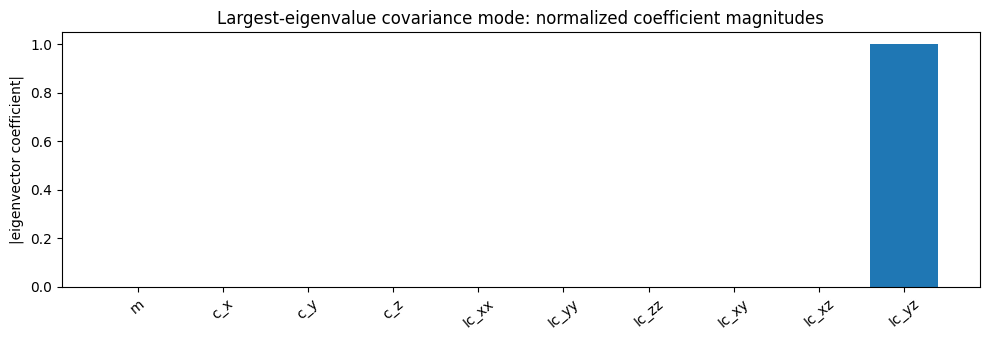

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from src.information_gain import select_nudge
from src.experiment_workflow import run_episode,summary,offline_coverage,paired_bootstrap,evaluate,save,teacher_data

env=make_env(ROOT,seed=SEED,noise=NOISE_STD,candidates=CANDIDATES,sample_s=SAMPLE_PERIOD_S,debug=True,trace=True)
P0=current_cov(env.est)
print('Physical units and scales:',list(zip(NAMES,UNITS,D)))
for mode in weak_modes(P0,3):
    print('Weak covariance eigenmode',mode['rank'],'norm-sd=',round(mode['sd_normalized'],4),
          'dominant coefficients:',mode['dominant'])
chosen=select_nudge(env.surface,env.est,env.est.last_state,env.dcfg,env.icfg,seed=SEED)
print('Selected nudge:',{'impulse_Ns':chosen['nudge'].impulse,'force_N':chosen['nudge'].force,
                        'point_body':chosen['nudge'].point.round(3).tolist(),
                        'direction_body':chosen['nudge'].push.round(3).tolist(),
                        'utility':round(chosen['utility'],4),
                        'expected_EIG_nats':round(chosen['parts']['gaussian_EIG_nats'],4)})
unc_table=pd.DataFrame({'parameter':NAMES,'before_std':chosen['parts']['before_std_physical'],
    'predicted_after_std':chosen['parts']['after_std_physical'],'units':UNITS})
display(unc_table)
plt.figure(figsize=(10,3.5))
plt.bar(NAMES, np.abs(chosen['parts']['weak_mode']))
plt.title('Largest-eigenvalue covariance mode: normalized coefficient magnitudes')
plt.ylabel('|eigenvector coefficient|');plt.xticks(rotation=40);plt.tight_layout();plt.show()
env.close()

## 5 · Continuous-estimation diagnostic: three nudges, updated at every sensor sample

Continuous measurement updates: 372
Final errors (simulation oracle only): {'mass_error_kg': 0.11077641691372264, 'com_error_mm': 0.12512900100423138, 'inertia_error_kgm2': 2.0610087931672556}
Nudge-by-nudge predicted vs observed uncertainty-proxy EIG (nats):
 nudge  predicted_eig_nats  passive_eig_nats  incremental_eig_over_passive_nats  observed_covariance_proxy_nats  impulse_Ns
     1              43.590            35.687                              7.903                          46.959       1.596
     2              14.262             6.735                              7.527                          13.613       1.861
     3               5.271             3.243                              2.029                           5.939       1.990
Weakest modes before each nudge:
[('Ic_yz', 1.0), ('m', 0.0), ('c_x', 0.0), ('c_y', 0.0)]
[('m', 1.0), ('c_x', 0.0), ('c_z', -0.0), ('c_y', 0.0)]
[('Ic_xz', 0.792), ('Ic_yz', -0.3596), ('Ic_yy', -0.2989), ('Ic_zz', 0.2757)]


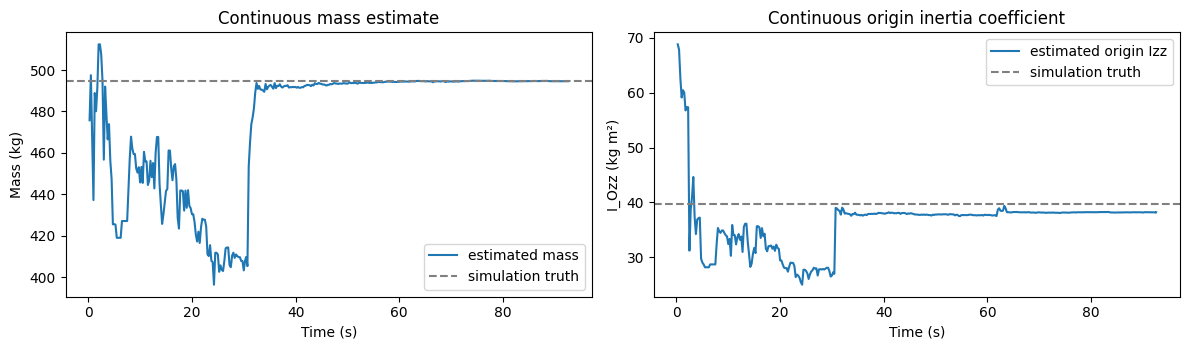

Nudge 1 estimated central Izz = 25.6322 kg m²; error in full tensor = 21.283 kg m²
Nudge 2 estimated central Izz = 37.5146 kg m²; error in full tensor = 3.026 kg m²
Nudge 3 estimated central Izz = 38.2139 kg m²; error in full tensor = 2.061 kg m²


In [7]:
env=make_env(ROOT,seed=SEED,noise=NOISE_STD,candidates=CANDIDATES,
             sample_s=DIAGNOSTIC_PERIOD_S,debug=True,trace=True)
row,steps,trace=run_episode(env,SEED,'oed_v11',include_trace=True)
assert row['success'] and len(steps)==3
print('Continuous measurement updates:',row['continuous_estimator_updates'])
print('Final errors (simulation oracle only):',
     {key:row[key] for key in ['mass_error_kg','com_error_mm','inertia_error_kgm2']})
print('Nudge-by-nudge predicted vs observed uncertainty-proxy EIG (nats):')
print(pd.DataFrame([{k:s[k] for k in ['nudge','predicted_eig_nats','passive_eig_nats','incremental_eig_over_passive_nats','observed_covariance_proxy_nats',
                                'impulse_Ns']} for s in steps]).round(3).to_string(index=False))
print('Weakest modes before each nudge:',*[s['weakest_mode_before'][0]['dominant'] for s in steps],sep='\n')
(OUT/'diagnostic_nudges.json').write_text(__import__('json').dumps(steps,indent=2,default=str))
# Trace from HybridEstimator updates, not the ground truth trajectory.
trace_df=pd.DataFrame([{'time_s':r['time_s'],
    **{f'pi_{i}':r['estimated_pi'][i] for i in range(10)},
    'committed_pairs':r['committed_momentum_pairs']} for r in env.est.trace])
trace_df.to_csv(OUT/'diagnostic_continuous_pi_trace.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=(12,3.6))
ax[0].plot(trace_df.time_s,trace_df.pi_0,label='estimated mass')
ax[0].axhline(env.truth_pi[0],linestyle='--',color='gray',label='simulation truth')
ax[0].set(xlabel='Time (s)',ylabel='Mass (kg)',title='Continuous mass estimate');ax[0].legend()
ax[1].plot(trace_df.time_s,trace_df.pi_6,label='estimated origin Izz')
ax[1].axhline(env.truth_pi[6],linestyle='--',color='gray',label='simulation truth')
ax[1].set(xlabel='Time (s)',ylabel='I_Ozz (kg m²)',title='Continuous origin inertia coefficient');ax[1].legend()
plt.tight_layout();fig.savefig(OUT/'continuous_estimates.png',dpi=160);plt.show()
# Compare physically meaningful central inertia after each nudge.
for s in steps:
    if s['pi_est']:
        central=theta_from_pi(np.asarray(s['pi_est'],float))
        print(f"Nudge {s['nudge']} estimated central Izz = {central[6]:.4f} kg m²; "+
              f"error in full tensor = {s['inertia_error_kgm2']:.3f} kg m²")
env.close()

## 6 · Offline covariance calibration (simulation truth is used ONLY for reporting)

In [8]:
cal_seeds=range(31000,31000+CALIBRATION_EPISODES)
cal_df,cal_nudges=evaluate(ROOT,cal_seeds,policies=('oed_v11',),
    noise=NOISE_STD,candidates=CANDIDATES,sample_s=SAMPLE_PERIOD_S,progress=False)
cal_dir=save(ROOT,cal_df,cal_nudges,OUT.relative_to(ROOT)/'calibration_only')
coverage=offline_coverage(cal_df,'oed_v11')
coverage.to_csv(OUT/'calibration_coverage_by_parameter.csv',index=False)
display(coverage.round(3))
print('Desired Gaussian nominal coverage: ~95%, with finite-sample variation.')
if len(coverage):
    print('BEWARE: observed <80% coverage for:',coverage.loc[coverage.empirical_95pct_coverage<.8,'parameter'].tolist())
print('This is a diagnostic, NOT a corrected or certified covariance. No calibration-set truth is used to choose an evaluation nudge.')

,parameter,episodes,empirical_95pct_coverage,median_abs_z,p90_abs_z,rms_z
0,m,40,0.975,0.800,1.799,1.081
1,c_x,40,0.975,0.570,1.612,0.909
2,c_y,40,0.975,0.702,1.513,0.986
3,c_z,40,0.975,0.753,1.369,0.966
4,Ic_xx,40,1.000,0.649,1.340,0.857
5,Ic_yy,40,0.975,0.476,1.324,0.791
6,Ic_zz,40,1.000,0.536,0.864,0.663
7,Ic_xy,40,1.000,0.465,0.943,0.599
8,Ic_xz,40,1.000,0.355,0.719,0.490
9,Ic_yz,40,1.000,0.347,0.953,0.568


Desired Gaussian nominal coverage: ~95%, with finite-sample variation.
BEWARE: observed <80% coverage for: []
This is a diagnostic, NOT a corrected or certified covariance. No calibration-set truth is used to choose an evaluation nudge.


## 7 · Train SAC with periodic **model + replay-buffer** checkpoints

The full study trains for **120,000** environment steps (about 40,000 three-nudge episodes). This is a target number of steps, **not** a promised two-hour wall-clock duration. The training loop periodically saves the neural policy and its replay buffer so an interruption does not erase all progress. To resume an interrupted run, set `RESUME_TRAINING = True` in Section 0 and **Run All** again; this skips behavior cloning and loads the newest complete checkpoint. A resumed run is not necessarily bit-for-bit identical to uninterrupted training because random-number-generator and environment states are not fully serialized.

**If you want a clean independent run**, leave `RESUME_TRAINING = False`. This will overwrite files with the *same names inside the v11.1 output folder*, so copy that folder elsewhere first when preserving an earlier v11.1 trial. All previous v11 folders remain separate.


OED teacher decisions: 480 from 160 episodes
Using cpu device
Wrapping the env in a DummyVecEnv.
Behavior cloning: 480 decisions, loss 0.45178 -> 0.21412


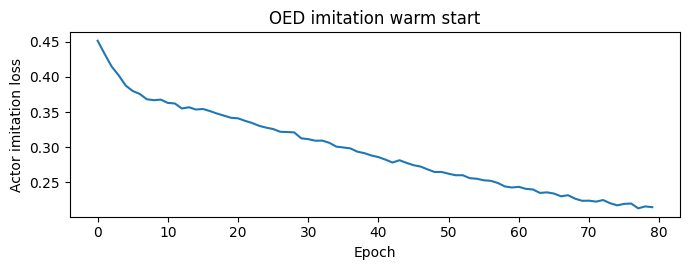

Current steps: 0; target: 120,000; remaining: 120,000
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 3        |
|    ep_rew_mean     | 2.37     |
| time/              |          |
|    episodes        | 4        |
|    fps             | 15       |
|    time_elapsed    | 0        |
|    total_timesteps | 12       |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 3        |
|    ep_rew_mean     | 2.3      |
| time/              |          |
|    episodes        | 8        |
|    fps             | 15       |
|    time_elapsed    | 1        |
|    total_timesteps | 24       |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 3        |
|    ep_rew_mean     | 2.51     |
| time/              |          |
|    episodes        | 12       |
|    fps             | 15       |
|    time_elapsed    | 2    

In [9]:
from stable_baselines3 import SAC
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import CheckpointCallback
from src.nudge_v10_workflow import behavior_clone_actor

# The callback saves both actor/critic and the off-policy experience replay buffer.
# With one environment, callback save_freq equals the number of environment steps.
checkpoint_cb = CheckpointCallback(
    save_freq=CHECKPOINT_INTERVAL,
    save_path=str(CHECKPOINT_DIR),
    name_prefix=CHECKPOINT_PREFIX,
    save_replay_buffer=True,
    verbose=2,
)

def find_latest_complete_checkpoint():
    matches = []
    for model_file in CHECKPOINT_DIR.glob(f'{CHECKPOINT_PREFIX}_*_steps.zip'):
        match = re.fullmatch(rf'{re.escape(CHECKPOINT_PREFIX)}_(\d+)_steps\.zip', model_file.name)
        if match:
            step = int(match.group(1))
            buffer_file = CHECKPOINT_DIR/f'{CHECKPOINT_PREFIX}_replay_buffer_{step}_steps.pkl'
            if buffer_file.exists():
                matches.append((step, model_file, buffer_file))
    return max(matches, key=lambda item:item[0]) if matches else None

train_start = time.perf_counter()
train_env = Monitor(make_env(ROOT,noise=NOISE_STD,candidates=CANDIDATES,
                             sample_s=SAMPLE_PERIOD_S,debug=False,trace=False))
try:
    if RESUME_TRAINING:
        latest = find_latest_complete_checkpoint()
        if latest is None:
            raise FileNotFoundError('No complete model+replay-buffer checkpoint exists; use RESUME_TRAINING=False for a new run.')
        recovered_steps,model_file,buffer_file = latest
        print('Resuming at saved timestep',recovered_steps,'from',model_file.name)
        sac = SAC.load(str(model_file),env=train_env,device='cpu')
        sac.load_replay_buffer(str(buffer_file))
        if int(sac.num_timesteps) != recovered_steps:
            raise RuntimeError(f'Checkpoint timestep mismatch: {sac.num_timesteps} vs {recovered_steps}')
        print('Loaded experience buffer; skipping teacher generation and BC on resume.')
    else:
        teacher_seeds = range(1000,1000+TEACHER_EPISODES)
        X_teacher,Y_teacher,G_teacher = teacher_data(
            ROOT,teacher_seeds,candidates=CANDIDATES,noise=NOISE_STD,sample_s=SAMPLE_PERIOD_S)
        print('OED teacher decisions:',len(X_teacher),'from',len(set(G_teacher)),'episodes')
        sac = SAC('MlpPolicy',train_env,seed=SEED,verbose=1,device='cpu',
            learning_starts=150,buffer_size=50000,batch_size=128,
            gamma=.99,policy_kwargs=dict(net_arch=[128,128]))
        bc_history = behavior_clone_actor(sac,X_teacher,Y_teacher,epochs=BC_EPOCHS,
                                          batch_size=64,verbose=True)
        plt.figure(figsize=(7,2.8));plt.plot(bc_history)
        plt.title('OED imitation warm start');plt.xlabel('Epoch');plt.ylabel('Actor imitation loss')
        plt.tight_layout();plt.show()
        sac.save(str(OUT/'sac_after_imitation_before_SAC'))

    already = int(sac.num_timesteps)
    remaining = max(0, TRAIN_TIMESTEPS-already)
    print(f'Current steps: {already:,}; target: {TRAIN_TIMESTEPS:,}; remaining: {remaining:,}')
    if remaining:
        sac.learn(total_timesteps=remaining,reset_num_timesteps=False,callback=checkpoint_cb)
    else:
        print('Training target already reached; reusing loaded model.')
    sac.save(str(MODEL_PATH))
    sac.save_replay_buffer(str(OUT/'sac_uncertainty_v11_extended_final_replay_buffer.pkl'))
finally:
    train_env.close()

training_seconds = time.perf_counter()-train_start
record = dict(total_timesteps=int(sac.num_timesteps), training_cell_wall_seconds=training_seconds,
              training_target=TRAIN_TIMESTEPS,checkpoint_interval=CHECKPOINT_INTERVAL,
              resumed=RESUME_TRAINING,quick_mode=QUICK_MODE,noise_std=NOISE_STD,
              sample_period_s=SAMPLE_PERIOD_S,seed=SEED)
(OUT/'training_run_metadata.json').write_text(json.dumps(record,indent=2))
print('Saved final model:',str(MODEL_PATH)+'.zip')
print('Saved final replay buffer and intermediate checkpoints under:',CHECKPOINT_DIR)
print(f'Training cell elapsed: {training_seconds/60:.1f} min (includes BC if starting fresh).')


## 7b · Compare SAC checkpoints against OED using the **same held-out seeds**

This tests whether extending training beyond 40k actually improves the **final three-nudge parameter errors**, rather than only the RL reward. In full mode, evaluation compares checkpoints at 40k, 80k and 120k timesteps, plus OED on one common set of 16 seeds. These 16 seeds (`90000+`) are disjoint from training, teacher, distillation and the main 60-seed evaluation. This is **diagnostic checkpoint selection**; use the independent 60-seed comparison below for your research results. Never tune the policy repeatedly against that final held-out set.


,policy,episodes,successes,mass_error_kg_median,com_error_mm_median,inertia_error_kgm2_median,total_reward_mean
0,oed_v11,16,16,0.0861,0.1646,1.9036,4.2374
1,rl_120k,16,16,0.0813,0.1192,2.8964,4.2767
2,rl_40k,16,16,0.0660,0.1137,3.8574,3.8237
3,rl_80k,16,16,0.0840,0.1294,4.1029,3.9907


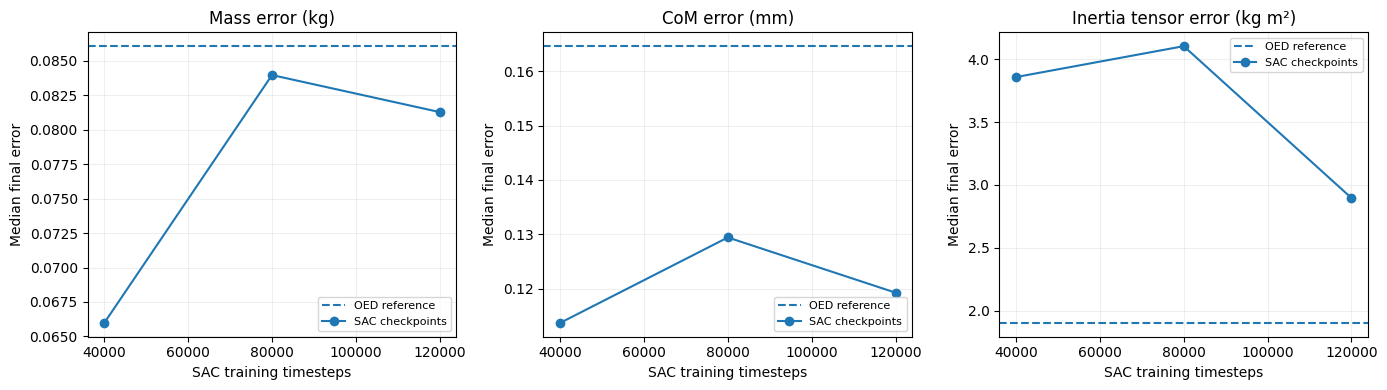

In [10]:
from src.experiment_workflow import summary
import gc

checkpoint_seeds = range(90000, 90000+CHECKPOINT_EVAL_EPISODES)
oed_stage_df, _ = evaluate(ROOT,checkpoint_seeds,policies=('oed_v11',),
    noise=NOISE_STD,candidates=CANDIDATES,sample_s=SAMPLE_PERIOD_S,progress=False)
oed_stage_df['training_steps'] = 0  # constant analytical reference, not an RL checkpoint
stage_frames = []
for step in STAGE_TIMESTEPS:
    model_file = CHECKPOINT_DIR/f'{CHECKPOINT_PREFIX}_{step}_steps.zip'
    if not model_file.exists():
        print('Skipping missing checkpoint:',model_file.name)
        continue
    checkpoint_model = SAC.load(str(model_file),device='cpu')
    stage_df,_ = evaluate(ROOT,checkpoint_seeds,policies=('rl',),model=checkpoint_model,
        noise=NOISE_STD,candidates=CANDIDATES,sample_s=SAMPLE_PERIOD_S,progress=False)
    stage_df['training_steps'] = step
    stage_df['policy'] = f'rl_{step//1000}k'
    stage_frames.append(stage_df)
    del checkpoint_model
    gc.collect()
checkpoints_df = pd.concat([oed_stage_df,*stage_frames],ignore_index=True)
checkpoints_df.to_csv(OUT/'checkpoint_accuracy_episodes.csv',index=False)
checkpoint_stats = summary(checkpoints_df)
checkpoint_stats.to_csv(OUT/'checkpoint_accuracy_summary.csv',index=False)
display(checkpoint_stats[['policy','episodes','successes',
    'mass_error_kg_median','com_error_mm_median','inertia_error_kgm2_median',
    'total_reward_mean']].round(4))

if stage_frames:
    fig,axes = plt.subplots(1,3,figsize=(14,4))
    targets = [('mass_error_kg','Mass error (kg)'),
               ('com_error_mm','CoM error (mm)'),
               ('inertia_error_kgm2','Inertia tensor error (kg m²)')]
    for ax,(metric,label) in zip(axes,targets):
        oed_med = oed_stage_df.loc[oed_stage_df.success,metric].median()
        ax.axhline(oed_med,linestyle='--',label='OED reference')
        xs = [int(g.training_steps.iloc[0]) for g in stage_frames]
        ys = [g.loc[g.success,metric].median() for g in stage_frames]
        ax.plot(xs,ys,marker='o',label='SAC checkpoints')
        ax.set(title=label,xlabel='SAC training timesteps',ylabel='Median final error')
        ax.grid(alpha=.2);ax.legend(fontsize=8)
    plt.tight_layout();fig.savefig(OUT/'checkpoint_accuracy_curves.png',dpi=160);plt.show()
else:
    print('No requested intermediate checkpoints available; final model is still saved.')

## 8 · Matched-policy final evaluation on entirely new seeds
Checkpoint-seed diagnostics above and final evaluation seeds below are disjoint.


,policy,episodes,successes,mass_error_kg_median,mass_error_kg_mean,mass_error_kg_p90,com_error_mm_median,com_error_mm_mean,com_error_mm_p90,inertia_error_kgm2_median,...,coverage95_m_rate,coverage95_c_x_rate,coverage95_c_y_rate,coverage95_c_z_rate,coverage95_Ic_xx_rate,coverage95_Ic_yy_rate,coverage95_Ic_zz_rate,coverage95_Ic_xy_rate,coverage95_Ic_xz_rate,coverage95_Ic_yz_rate
0,hybrid_v11,60,60,0.1039,0.1363,0.2894,0.0846,0.1346,0.3111,1.9523,...,0.9000,0.9500,0.9333,0.9333,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,oed_v10,60,60,0.0999,0.1248,0.2865,0.0853,0.1291,0.3178,2.0457,...,0.9333,0.9500,0.9333,0.9833,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
2,oed_v11,60,60,0.0999,0.1264,0.2769,0.0880,0.1331,0.3178,2.1259,...,0.9167,0.9667,0.9500,0.9667,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
3,random,60,60,0.2762,0.3687,0.6393,0.1590,0.4081,1.0409,14.6743,...,0.9500,0.9667,0.9333,0.9667,0.5167,0.6167,0.6167,0.9167,1.0000,0.9167
4,rl,60,60,0.1372,0.1717,0.3314,0.1363,0.2431,0.5180,4.8139,...,0.9000,0.8833,0.8833,0.9000,0.9500,0.9667,0.9500,0.9667,0.9833,1.0000


Paired OED_v11 vs RL inertia: {'pairs': 60, 'mean_paired_difference': -3.5567023898897285, 'median_paired_difference': -2.4422735750773303, 'fraction_a_lower_error': 0.7833333333333333, 'mean_difference_bootstrap_95pct': [-4.833965641751542, -2.4060585781572925], 'note': 'Bootstrap uncertainty reflects finite episode sampling, not model mismatch.'}
Paired OED_v11 vs OED_v10 inertia: {'pairs': 60, 'mean_paired_difference': 0.049450869945461204, 'median_paired_difference': 0.0, 'fraction_a_lower_error': 0.1, 'mean_difference_bootstrap_95pct': [-0.03489926109944116, 0.13556951703788914], 'note': 'Bootstrap uncertainty reflects finite episode sampling, not model mismatch.'}
Paired hybrid_v11 vs OED_v11 inertia: {'pairs': 60, 'mean_paired_difference': -0.2693380941071655, 'median_paired_difference': 0.0, 'fraction_a_lower_error': 0.3, 'mean_difference_bootstrap_95pct': [-0.5114727140147456, -0.05701192906273516], 'note': 'Bootstrap uncertainty reflects finite episode sampling, not model mis

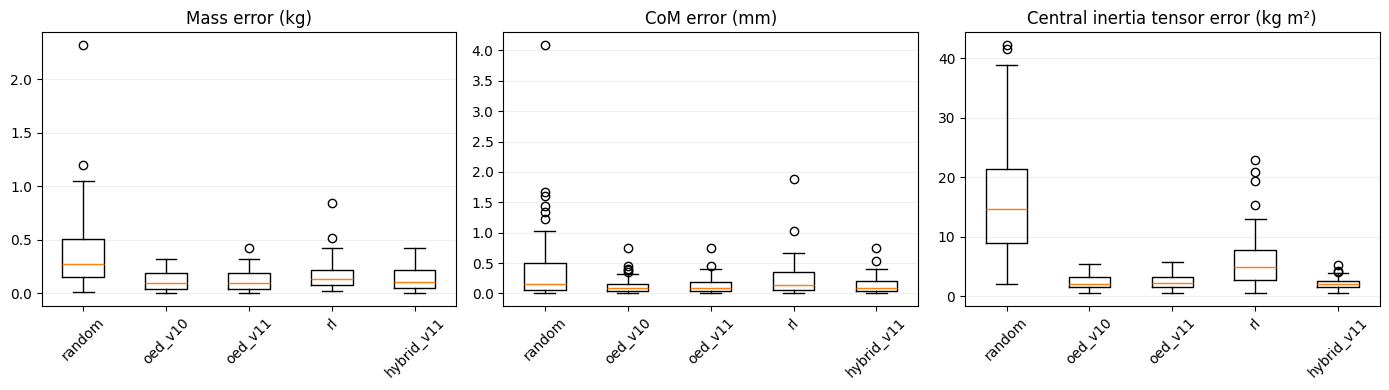

In [11]:
from src.experiment_workflow import paired_bootstrap,offline_coverage

policies=['random','oed_v10','oed_v11','rl','hybrid_v11']
eval_seeds=range(50000,50000+EVALUATION_EPISODES)
df,nudge_records=evaluate(ROOT,eval_seeds,policies=policies,model=sac,
    noise=NOISE_STD,candidates=CANDIDATES,sample_s=SAMPLE_PERIOD_S,progress=QUICK_MODE)
eval_dir=save(ROOT,df,nudge_records,OUT.relative_to(ROOT)/'matched_evaluation')
stat=summary(df)
display(stat.round(4))
print('Paired OED_v11 vs RL inertia:',paired_bootstrap(df,'oed_v11','rl'))
print('Paired OED_v11 vs OED_v10 inertia:',paired_bootstrap(df,'oed_v11','oed_v10'))
print('Paired hybrid_v11 vs OED_v11 inertia:',paired_bootstrap(df,'hybrid_v11','oed_v11'))
print('Hybrid RL-selected nudges:',int(df.loc[df.policy=='hybrid_v11','selected_from_rl'].sum()))
fig,axs=plt.subplots(1,3,figsize=(14,4))
for ax,key,title in zip(axs,['mass_error_kg','com_error_mm','inertia_error_kgm2'],
                        ['Mass error (kg)','CoM error (mm)','Central inertia tensor error (kg m²)']):
    available=[p for p in policies if ((df.policy==p)&df.success).any()]
    ax.boxplot([df[(df.policy==p)&df.success][key].dropna() for p in available],tick_labels=available)
    ax.tick_params(axis='x',rotation=45);ax.set_title(title);ax.grid(axis='y',alpha=.2)
plt.tight_layout();fig.savefig(OUT/'policy_errors.png',dpi=160);plt.show()

## 8b · Optional comparison with saved v9 and v10 SAC checkpoints (same v11 estimator and seeds)

In [12]:
previous_paths = {
    'v9_checkpoint': ROOT/'results'/'three_nudge_v9'/'sac_hybrid_v9.zip',
    'v10_checkpoint': ROOT/'results'/'three_nudge_v10'/'sac_oed_warmstart_v10.zip',
}
prev_rows=[]
for label,checkpoint in previous_paths.items():
    if not checkpoint.exists():
        print('No saved checkpoint, skip:',checkpoint)
        continue
    try:
        old_model=SAC.load(str(checkpoint),device='cpu')
        old_df,_=evaluate(ROOT,eval_seeds,policies=('rl',),model=old_model,
            noise=NOISE_STD,candidates=CANDIDATES,sample_s=SAMPLE_PERIOD_S,progress=False)
        old_df['policy']=label
        prev_rows.append(old_df)
        print('Evaluated:',label)
    except (ValueError,TypeError,RuntimeError,ImportError) as exc:
        print('Unable to load checkpoint',label,repr(exc))
if prev_rows:
    comparisons=pd.concat([*prev_rows,df[df.policy=='rl'].assign(policy='v11_sac')],ignore_index=True)
    comparisons.to_csv(OUT/'historical_SAC_comparison.csv',index=False)
    display(summary(comparisons).round(4))
else:
    print('No previous SAC checkpoint found. v11 evaluation is still complete.')

Evaluated: v9_checkpoint
Evaluated: v10_checkpoint


,policy,episodes,successes,mass_error_kg_median,mass_error_kg_mean,mass_error_kg_p90,com_error_mm_median,com_error_mm_mean,com_error_mm_p90,inertia_error_kgm2_median,...,coverage95_m_rate,coverage95_c_x_rate,coverage95_c_y_rate,coverage95_c_z_rate,coverage95_Ic_xx_rate,coverage95_Ic_yy_rate,coverage95_Ic_zz_rate,coverage95_Ic_xy_rate,coverage95_Ic_xz_rate,coverage95_Ic_yz_rate
0,v10_checkpoint,60,60,0.1235,0.1543,0.2970,0.1373,0.2421,0.6153,4.2726,...,0.9167,0.9500,0.9167,0.9500,0.9833,0.9500,0.9167,0.9833,1.0000,0.9667
1,v11_sac,60,60,0.1372,0.1717,0.3314,0.1363,0.2431,0.5180,4.8139,...,0.9000,0.8833,0.8833,0.9000,0.9500,0.9667,0.9500,0.9667,0.9833,1.0000
2,v9_checkpoint,60,60,0.1087,0.1550,0.3239,0.1717,0.2754,0.6766,5.1140,...,0.9000,0.9667,0.9500,0.9167,0.9000,0.8833,0.9500,0.9167,0.9833,0.9833


## 9 · Per-nudge information, physical torque axes, and predictive reliability

predicted_eig_nats  incremental_eig_over_passive_nats  \
policy     nudge                                                          
hybrid_v11 1                  35.845                              8.870   
           2                  22.129                             14.621   
           3                   5.329                              1.874   
oed_v10    1                  35.742                              8.733   
           2                  21.728                             14.405   
           3                   5.190                              1.771   
oed_v11    1                  35.724                              8.760   
           2                  21.810                             14.308   
           3                   5.183                              1.745   
random     1                  31.265                              4.353   
           2                  17.217                              9.318   
           3                   6.038                              1.988   
rl         1                  33.069                              6.140   
           2                  22.416                             14.943   
           3                   5.763                              2.146   

                  observed_covariance_proxy_nats  
policy     nudge                                  
hybrid_v11 1                              39.935  
           2                              16.288  
           3                               5.913  
oed_v10    1                              39.899  
           2                              16.110  
           3                               5.787  
oed_v11    1                              39.863  
           2                              16.131  
           3                               5.779  
random     1                              35.796  
           2                              14.518  
           3                               5.979  
rl         1                              37.338  
           2                              16.676  
           3                               6.121

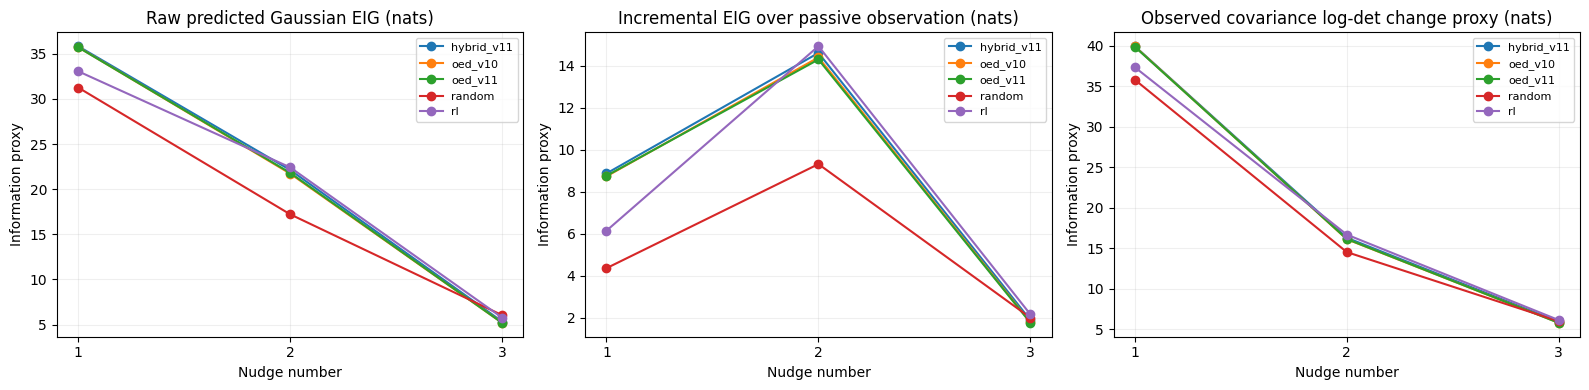

tau_x_impulse  tau_y_impulse  tau_z_impulse
policy     nudge                                             
hybrid_v11 1              0.181          0.169          0.117
           2              0.163          0.188          0.180
           3              0.183          0.204          0.125
oed_v10    1              0.173          0.156          0.123
           2              0.157          0.162          0.161
           3              0.163          0.159          0.128
oed_v11    1              0.175          0.157          0.125
           2              0.144          0.163          0.171
           3              0.171          0.160          0.124
random     1              0.058          0.061          0.045
           2              0.064          0.067          0.061
           3              0.052          0.059          0.052
rl         1              0.114          0.128          0.042
           2              0.214          0.184          0.119
           3              0.146          0.161          0.105

Prequential prediction residuals: frozen BEFORE receiving each nudge response.


,position_m,velocity_mps,omega_radps,orientation_rad
policy,,,,
hybrid_v11,0.018510,0.000728,0.008529,0.133828
oed_v10,0.018261,0.000739,0.008070,0.118196
oed_v11,0.018314,0.000728,0.008287,0.126305
random,0.010511,0.000539,0.006287,0.092846
rl,0.015210,0.000612,0.007769,0.124598


In [13]:
nn=pd.DataFrame([{k:r.get(k) for k in ('seed','policy','nudge','selected_from','predicted_eig_nats',
    'incremental_eig_over_passive_nats','observed_covariance_proxy_nats','impulse_Ns','mass_error_kg','com_error_mm','inertia_error_kgm2')} for r in nudge_records])
display(nn.groupby(['policy','nudge'])[['predicted_eig_nats','incremental_eig_over_passive_nats','observed_covariance_proxy_nats']].mean().round(3))
fig,axs=plt.subplots(1,3,figsize=(16,4))
for name,grp in nn.groupby('policy'):
    gr=grp.groupby('nudge')[['predicted_eig_nats','incremental_eig_over_passive_nats','observed_covariance_proxy_nats']].mean()
    axs[0].plot(gr.index,gr.predicted_eig_nats,marker='o',label=name)
    axs[1].plot(gr.index,gr.incremental_eig_over_passive_nats,marker='o',label=name)
    axs[2].plot(gr.index,gr.observed_covariance_proxy_nats,marker='o',label=name)
for ax,title in zip(axs,['Raw predicted Gaussian EIG (nats)','Incremental EIG over passive observation (nats)','Observed covariance log-det change proxy (nats)']):
    ax.set(xlabel='Nudge number',ylabel='Information proxy',title=title)
    ax.set_xticks([1,2,3]);ax.legend(fontsize=8);ax.grid(alpha=.2)
plt.tight_layout();fig.savefig(OUT/'information_by_nudge.png',dpi=160);plt.show()
# Which axes do the planned nudges actually excite?  Body-frame angular impulse about estimated CoM.
ang=pd.DataFrame([{'seed':r['seed'],'policy':r['policy'],'nudge':r['nudge'],
  **dict(zip(['tau_x_impulse','tau_y_impulse','tau_z_impulse'],r['angular_impulse_about_est_CoM_Nms']))}
   for r in nudge_records if 'angular_impulse_about_est_CoM_Nms' in r])
ang.to_csv(OUT/'angular_impulses_body.csv',index=False)
display(ang.groupby(['policy','nudge'])[['tau_x_impulse','tau_y_impulse','tau_z_impulse']].apply(lambda g:g.abs().mean()).round(3))
resids=pd.DataFrame([{'policy':r['policy'],'seed':r['seed'],'nudge':r['nudge'],
  **r['prequential_prediction_residual']} for r in nudge_records
  if isinstance(r.get('prequential_prediction_residual'),dict)])
resids.to_csv(OUT/'prequential_prediction_residuals.csv',index=False)
print('Prequential prediction residuals: frozen BEFORE receiving each nudge response.')
display(resids.groupby('policy')[['position_m','velocity_mps','omega_radps','orientation_rad']].median().round(6))

## 10 · Test Gaussian 95% coverage on independent evaluation seeds

In [14]:
evaluation_coverage=offline_coverage(df,'oed_v11')
evaluation_coverage.to_csv(OUT/'heldout_eval_coverage_by_parameter.csv',index=False)
display(evaluation_coverage.round(3))
print('Calibration and evaluation were disjoint: calibration seeds 31000+, evaluation seeds 50000+.')
print('A low empirical coverage rate flags an overconfident local covariance; do NOT trust it for flight safety decisions.')

,parameter,episodes,empirical_95pct_coverage,median_abs_z,p90_abs_z,rms_z
0,m,60,0.917,0.613,1.618,1.000
1,c_x,60,0.967,0.643,1.601,0.941
2,c_y,60,0.950,0.642,1.551,0.976
3,c_z,60,0.967,0.556,1.513,0.904
4,Ic_xx,60,1.000,0.635,1.335,0.844
5,Ic_yy,60,1.000,0.707,1.314,0.816
6,Ic_zz,60,1.000,0.498,1.335,0.716
7,Ic_xy,60,1.000,0.449,1.119,0.654
8,Ic_xz,60,1.000,0.498,0.942,0.585
9,Ic_yz,60,1.000,0.405,0.787,0.525


Calibration and evaluation were disjoint: calibration seeds 31000+, evaluation seeds 50000+.
A low empirical coverage rate flags an overconfident local covariance; do NOT trust it for flight safety decisions.


## 11 · Distill the RL network to interpretable decision-tree rules and test in closed loop

In [15]:
from src.nudge_v10_workflow import distill_tree
from pathlib import Path

# Group-aware train / validation / holdout splits across entire episodes.
distill_seeds=range(20000,20000+DISTILL_EPISODES)
Xt=[];Yt=[];Gt=[]
tree_env=make_env(ROOT,noise=NOISE_STD,candidates=CANDIDATES,sample_s=SAMPLE_PERIOD_S,debug=False)
try:
    for seed in distill_seeds:
        o,_=tree_env.reset(seed=int(seed))
        for j in range(3):
            a,_=sac.predict(o,deterministic=True)
            Xt.append(o.copy());Yt.append(a.copy());Gt.append(seed)
            o,r,done,trunc,info=tree_env.step(a)
            if info.get('failure_reason'):raise RuntimeError(info['failure_reason'])
            if done or trunc:break
finally:tree_env.close()
X=np.asarray(Xt,np.float32);Y=np.asarray(Yt,np.float32);G=np.asarray(Gt,int)
tree,report,rules=distill_tree(X,Y,G,
    depth_choices=(3,4,6,8,10),min_samples_leaf=2 if QUICK_MODE else 4,
    output_dir=OUT/'distilled_rl_rules')
(OUT/'distilled_rl_rules'/'policy_rules_v11.txt').write_text(rules)
print('Episode-heldout action MAE (normalized):',report['holdout_action_MAE'])
print('Decision tree depth:',report['chosen_tree_depth'])
print('Rule preview:\n',rules[:2500])
# Importantly: evaluate the tree's THREE nudges, not merely its action MAE.
tree_df,tree_details=evaluate(ROOT,eval_seeds,policies=('tree',),tree=tree,
    noise=NOISE_STD,candidates=CANDIDATES,sample_s=SAMPLE_PERIOD_S,progress=False)
save(ROOT,tree_df,tree_details,OUT.relative_to(ROOT)/'distilled_rl_rules'/'closed_loop')
display(summary(tree_df).round(4))

Episode-heldout action MAE (normalized): 0.31443011665258097
Decision tree depth: 4
Rule preview:
 |--- log_cov_6 <= -0.2449
|   |--- cov_corr_2_3 <= -0.7088
|   |   |--- R_11 <= 0.6214
|   |   |   |--- cov_corr_1_3 <= 0.9212
|   |   |   |   |--- value: [-0.8991, -0.5590, 0.4052, 0.8770, 0.9562, 0.1568]
|   |   |   |--- cov_corr_1_3 >  0.9212
|   |   |   |   |--- value: [-0.6456, 0.2149, 0.7287, 0.8666, 0.9392, -0.3773]
|   |   |--- R_11 >  0.6214
|   |   |   |--- omega_x <= 0.0276
|   |   |   |   |--- value: [0.2274, 0.4018, -0.0108, 0.8049, 0.9334, 0.3533]
|   |   |   |--- omega_x >  0.0276
|   |   |   |   |--- value: [-0.8236, 0.3002, 0.3002, 0.9160, 0.9663, 0.4136]
|   |--- cov_corr_2_3 >  -0.7088
|   |   |--- log_cov_1 <= -0.6112
|   |   |   |--- R_00 <= 0.2946
|   |   |   |   |--- value: [0.8830, -0.8825, 0.4271, 0.9208, 0.9618, 0.0019]
|   |   |   |--- R_00 >  0.2946
|   |   |   |   |--- value: [0.3973, -0.1210, 0.2309, 0.8338, 0.9499, -0.5678]
|   |   |--- log_cov_1 >  -0.6112


,policy,episodes,successes,mass_error_kg_median,mass_error_kg_mean,mass_error_kg_p90,com_error_mm_median,com_error_mm_mean,com_error_mm_p90,inertia_error_kgm2_median,...,coverage95_m_rate,coverage95_c_x_rate,coverage95_c_y_rate,coverage95_c_z_rate,coverage95_Ic_xx_rate,coverage95_Ic_yy_rate,coverage95_Ic_zz_rate,coverage95_Ic_xy_rate,coverage95_Ic_xz_rate,coverage95_Ic_yz_rate
0,tree,60,60,0.1182,0.1643,0.313,0.1911,0.3555,0.8667,4.6235,...,0.95,0.9333,0.9167,0.95,0.9167,0.9333,0.9,1.0,0.9667,0.95


## 12 · Noise robustness: noiseless and 1e-4, same policy checkpoints

In [16]:
robust=[]
for noise in [0.,1e-4]:
    robust_df,robust_nudges=evaluate(ROOT,range(70000,70000+NOISE_SWEEP_EPISODES),
        policies=('random','oed_v11','rl'),model=sac,
        noise=noise,candidates=CANDIDATES,sample_s=SAMPLE_PERIOD_S,progress=False)
    robust_df['noise_std']=noise
    robust.append(robust_df)
robust_df=pd.concat(robust,ignore_index=True)
robust_df.to_csv(OUT/'noise_robustness.csv',index=False)
display(robust_df[robust_df.success].groupby(['noise_std','policy'])[
    ['mass_error_kg','com_error_mm','inertia_error_kgm2']].median().round(4))

mass_error_kg  com_error_mm  inertia_error_kgm2
noise_std policy                                                  
0.0000    oed_v11         0.0000        0.0000              0.0070
          random          0.0000        0.0000              0.0605
          rl              0.0000        0.0000              0.0143
0.0001    oed_v11         0.1342        0.1125              2.3447
          random          0.2153        0.1697             11.4351
          rl              0.1004        0.1461              3.1659

## 13 · Interpretation and flight-readiness boundary

- **Information policy:** the optimizer sees only the current parameter estimates, approximate covariance and measured state. No ground-truth mass/inertia is passed into its action selection or RL reward.
- **Active versus passive information:** the planner subtracts the predicted information from a same-duration no-nudge observation. Thus it optimizes incremental expected information due to **actively nudging**, not merely waiting.\n- **Predicted EIG vs observed proxy:** predicted EIG is calculated before a nudge from the local Gaussian observation model; the observed covariance log-det difference is calculated after online updates. The observed proxy is **not** ground-truth entropy reduction and is not a statistically verified EIG.
- **Parameter errors and coverage:** the simulation oracle is used only to evaluate errors and empirical coverage, never to train rewards or choose an action.
- **Weak modes:** eigenvectors are calculated in fixed scaled \([m,c,I_C]\) coordinates; they represent **uncertain linear combinations**, not necessarily one principal inertial axis. Axis excitation follows the torque impulse \((p-c)\times J\).
- **Validation:** the prequential forecast is made before each nudge, then compared with the later measured state without refitting that forecast. Persistent residual biases indicate model inadequacy. Full calibration should include realistic colored vision noise, contact force uncertainty, model mismatch, nuisance states, and an independent high-fidelity dynamics backend.
- **No CBF/contact physics:** this remains an instantaneous-impulse rigid-body **surrogate**. It cannot certify contact accessibility or spacecraft safety.
- **No guarantee v11 wins:** OED_v11 vs v10, RL and hybrid are compared on paired seeds and independent evaluation. Results must be inspected. If empirical 95% coverage is poor, the reported covariance cannot support a claim of physically calibrated knowledge.

Outputs are under `results/three_nudge_v11_quick` or `..._full`, including trained SAC ZIP, CSVs, per-nudge JSON, fitted tree/rules, figures and continuous traces. **Keep v10 files and results unchanged for reproducibility.**

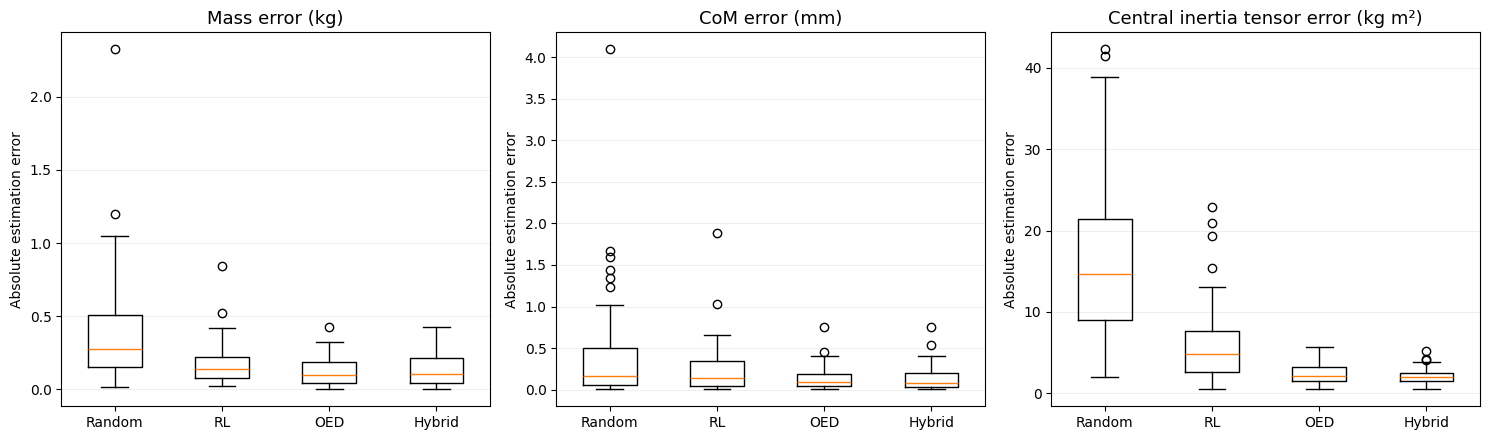

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

# Load previously saved evaluation results
results_file = OUT / "matched_evaluation" / "final_episode_metrics.csv"
plot_df = pd.read_csv(results_file)

# Include only successful episodes
plot_df = plot_df[
    plot_df["success"].astype(str).str.lower() == "true"
]

# Only the four requested methods, using OED version 11
methods = {
    "random": "Random",
    "rl": "RL",
    "oed_v11": "OED",
    "hybrid_v11": "Hybrid"
}

metrics = [
    ("mass_error_kg", "Mass error (kg)"),
    ("com_error_mm", "CoM error (mm)"),
    ("inertia_error_kgm2", "Central inertia tensor error (kg m²)")
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (metric, title) in zip(axes, metrics):

    data = [
        plot_df.loc[plot_df["policy"] == method, metric]
        .dropna()
        .to_numpy()
        for method in methods
    ]

    ax.boxplot(
        data,
        tick_labels=list(methods.values()),
        widths=0.5
    )

    ax.set_title(title, fontsize=13)
    ax.set_ylabel("Absolute estimation error")
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

# Save a new figure without overwriting the original
fig.savefig(
    OUT / "parameter_errors_four_methods.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()